---
title: "The Harmonic Oscillator — Level 2"
short_title: "03 Harmonic Oscillator"
numbering:
  heading_2: true
  equation: true
---

# The Harmonic Oscillator

:::{seealso} Math for this topic
- [Q-M2: Series solutions, Hermite and Laguerre functions](../math/02-series-solutions-special-functions.ipynb)
- [T-M2: Gaussian, Gamma and quantum-statistics integrals](../../level2-thermo-book/math/02-gaussian-gamma-integrals.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 35 | Energy quantization, zero-point energy |
| **2** | **Griffiths QM, ch. 2** | **Ladder operators, Hermite solutions, coherent states** |
| 3 | Sakurai, ch. 2 | Heisenberg picture, time evolution of operators, coherent and squeezed states |

The new skill at this level: solving a problem algebraically with operators that step between energy levels, instead of solving the differential equation

Math for this topic: Q-M2 (series solutions, Hermite functions) and thermo T-M2 (Gaussian integrals).
:::

Workbook example ladder: zero-point energy in numbers → the ladder-operator derivation → the time evolution of ⟨x⟩ in a coherent state. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Why the Oscillator Matters

Near any minimum, a potential is approximately a parabola: Taylor-expanding $V(x)$ about $x_0$ gives $V\approx V(x_0) + \tfrac12V''(x_0)(x - x_0)^2$ (mechanics M1). So the oscillator with $V = \tfrac12m\omega^2x^2$, $\omega = \sqrt{V''/m}$, describes small vibrations of molecules, atoms in solids (phonons, thermo topic 7), and the modes of the electromagnetic field (photons). It is the most reused exactly solvable problem in physics.

Its energies, which Q-M2 found from the requirement that a power series terminate, are

$$
E_n = \left(n + \tfrac12\right)\hbar\omega,\qquad n = 0, 1, 2, \ldots
$$ (eq-ho-levels)

evenly spaced, with a nonzero **zero-point energy** $\tfrac12\hbar\omega$.

::::{prf:example} Level 1 rung: the vibration of HCl
:label: ex-hcl-vibration

HCl absorbs infrared light at a wavenumber of 2886 cm⁻¹ (the $0\to1$ vibrational transition). Find $\hbar\omega$, the zero-point energy, and the bond's effective spring constant. (The reduced mass is $0.980$ u.)

:::{dropdown} Solution
$\hbar\omega = hc\tilde\nu = (1.240\times10^{-4}\text{ eV cm})(2886\text{ cm}^{-1}) = 0.358$ eV, so the zero-point energy is $0.179$ eV, about 7 times $kT$ at room temperature (why vibration is frozen, thermo topic 6). With $\omega = 5.44\times10^{14}$ s⁻¹ and $\mu = 1.63\times10^{-27}$ kg, $k = \mu\omega^2 = 481$ N/m: a stiff spring.
:::
::::

## Ladder Operators

Write the Hamiltonian as $\hat H = \frac{1}{2m}\left[\hat p^2 + (m\omega\hat x)^2\right]$. If $\hat x$ and $\hat p$ were numbers, it would factor as $(u + iv)(u - iv)$. They are not, but try anyway with

$$
\hat a_\pm = \frac{1}{\sqrt{2\hbar m\omega}}\left(\mp i\hat p + m\omega\hat x\right) .
$$ (eq-ladder-def)

The canonical commutator $[\hat x, \hat p] = i\hbar$ gives

$$
[\hat a_-, \hat a_+] = 1,\qquad \hat H = \hbar\omega\left(\hat a_+\hat a_- + \tfrac12\right) .
$$ (eq-ladder-algebra)

The factoring works up to the $\tfrac12$, which is the zero-point energy appearing from the commutator.

In [2]:
x = sp.symbols("x", real=True)
m, w, hb = sp.symbols("m omega hbar", positive=True)
f = sp.Function("f")(x)
p = lambda g: -sp.I * hb * sp.diff(g, x)
ap = lambda g: (-sp.I * p(g) + m * w * x * g) / sp.sqrt(2 * hb * m * w)
am = lambda g: (sp.I * p(g) + m * w * x * g) / sp.sqrt(2 * hb * m * w)
comm = sp.simplify(am(ap(f)) - ap(am(f)))
H = lambda g: p(p(g)) / (2 * m) + m * w**2 * x**2 * g / 2
display(Math(r"[\hat a_-,\hat a_+]f = " + sp.latex(comm)))
display(Math(r"\left(\hat H - \hbar\omega(\hat a_+\hat a_- + \tfrac12)\right)f = " + sp.latex(sp.simplify(H(f) - hb * w * (ap(am(f)) + f / 2)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**The ladder.** From {eq}`eq-ladder-algebra`, $[\hat H, \hat a_\pm] = \pm\hbar\omega\,\hat a_\pm$. So if $\psi$ has energy $E$, then $\hat a_+\psi$ has energy $E + \hbar\omega$ and $\hat a_-\psi$ has $E - \hbar\omega$: the operators raise and lower by one rung.

**The bottom rung.** Lowering cannot go on forever, since $\langle H\rangle\ge0$ for this potential. There must be a $\psi_0$ with $\hat a_-\psi_0 = 0$. That is a first-order ODE:

$$
\left(\hbar\frac{d}{dx} + m\omega x\right)\psi_0 = 0\quad\Rightarrow\quad\psi_0 = \left(\frac{m\omega}{\pi\hbar}\right)^{1/4}e^{-m\omega x^2/2\hbar},\qquad E_0 = \tfrac12\hbar\omega .
$$ (eq-ho-ground)

**Every other rung** follows by applying the raising operator, with normalization:

$$
\psi_n = \frac{1}{\sqrt{n!}}(\hat a_+)^n\psi_0,\qquad
\hat a_+\psi_n = \sqrt{n+1}\,\psi_{n+1},\qquad
\hat a_-\psi_n = \sqrt n\,\psi_{n-1} .
$$ (eq-ladder-action)

The second-order differential equation never had to be solved. The results agree with Q-M2's Hermite functions.

In [3]:
# Generate psi_1..psi_3 by applying a_+ to psi_0, and compare with the Hermite form
psi0 = (m * w / (sp.pi * hb))**sp.Rational(1, 4) * sp.exp(-m * w * x**2 / (2 * hb))
xi = sp.sqrt(m * w / hb) * x
psi = psi0
for n in range(1, 4):
    psi = sp.simplify(ap(psi) / sp.sqrt(n))
    herm = (m * w / (sp.pi * hb))**sp.Rational(1, 4) / sp.sqrt(2**n * sp.factorial(n)) * sp.hermite(n, xi) * sp.exp(-xi**2 / 2)
    display(Math(rf"\psi_{n} = " + sp.latex(psi) + (r"\quad\checkmark" if sp.simplify(psi - herm) == 0 else r"\quad\times")))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Expectation values without integrals

Invert {eq}`eq-ladder-def`: $\hat x = \sqrt{\hbar/2m\omega}\,(\hat a_+ + \hat a_-)$ and $\hat p = i\sqrt{\hbar m\omega/2}\,(\hat a_+ - \hat a_-)$. Then, for example,

$$
\langle n|\hat x^2|n\rangle = \frac{\hbar}{2m\omega}\langle n|(\hat a_+\hat a_- + \hat a_-\hat a_+)|n\rangle = \frac{\hbar}{2m\omega}(2n + 1) ,
$$

because the $\hat a_+^2$ and $\hat a_-^2$ terms change $n$ and give zero overlap. So $\langle V\rangle = \tfrac12m\omega^2\langle x^2\rangle = \tfrac12E_n$, and likewise $\langle T\rangle = \tfrac12E_n$ (a virial theorem). In the stationary state $\psi_n$, $\sigma_x\sigma_p = (n + \tfrac12)\hbar$, minimum (and Gaussian) only for $n = 0$.

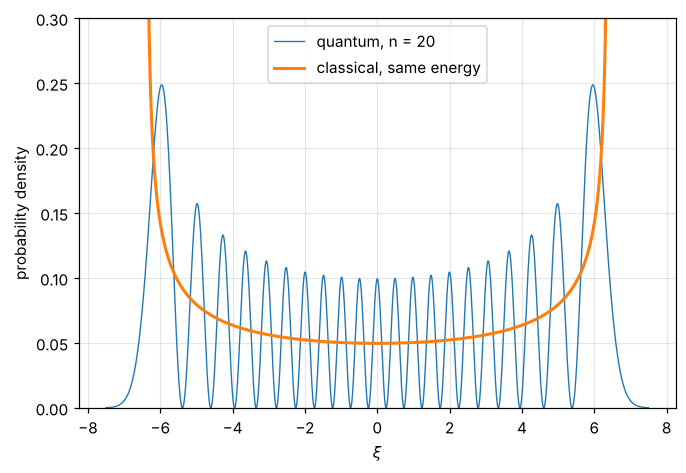

In [4]:
#| label: fig-ho-classical-limit
#| caption: "Probability density of the n = 20 oscillator state (blue) and of a classical oscillator with the same energy (orange), which spends most time near its turning points (density ∝ 1/√(A² − x²)). Averaged over the fast wiggles, the quantum density approaches the classical one at large n."
from scipy.special import eval_hermite, factorial
n = 20
X = np.linspace(-7.5, 7.5, 2000)       # xi units
P = (1 / np.sqrt(np.pi) / (2.0**n * factorial(n))) * eval_hermite(n, X)**2 * np.exp(-X**2)
A_ = np.sqrt(2 * n + 1)
Pc = np.where(np.abs(X) < A_, 1 / (np.pi * np.sqrt(np.clip(A_**2 - X**2, 1e-12, None))), np.nan)
fig, ax = plt.subplots()
ax.plot(X, P, lw=0.9, label=f"quantum, n = {n}"); ax.plot(X, Pc, lw=2, label="classical, same energy")
ax.set_ylim(0, 0.3); ax.set_xlabel("$\\xi$"); ax.set_ylabel("probability density"); ax.legend(); plt.show()

## Coherent States

Stationary states do not move, and a superposition of many of them is needed for anything that looks like a swinging mass. The best such superpositions are eigenstates of the *lowering* operator:

$$
\hat a_-|\alpha\rangle = \alpha|\alpha\rangle,\qquad
|\alpha\rangle = e^{-|\alpha|^2/2}\sum_{n=0}^\infty\frac{\alpha^n}{\sqrt{n!}}|n\rangle ,
$$ (eq-coherent-state)

for any complex number $\alpha$. ($\hat a_-$ is not Hermitian, so complex eigenvalues are fine.) Their properties:

- The probability of $n$ quanta is $|c_n|^2 = e^{-|\alpha|^2}|\alpha|^{2n}/n!$, a **Poisson distribution** with mean $\bar n = |\alpha|^2$.
- They stay coherent: each $|n\rangle$ picks up $e^{-i(n + 1/2)\omega t}$, so $|\alpha\rangle$ evolves into $e^{-i\omega t/2}|\alpha e^{-i\omega t}\rangle$, still a coherent state.
- Hence $\langle x\rangle = \sqrt{2\hbar/m\omega}\,|\alpha|\cos(\omega t - \phi)$: exactly the classical motion.
- The wave packet is a Gaussian with the ground state's width that never spreads, and $\sigma_x\sigma_p = \hbar/2$ at all times.

Laser light is, to a good approximation, a coherent state of a field mode, which is why photon counts from a laser are Poisson distributed.

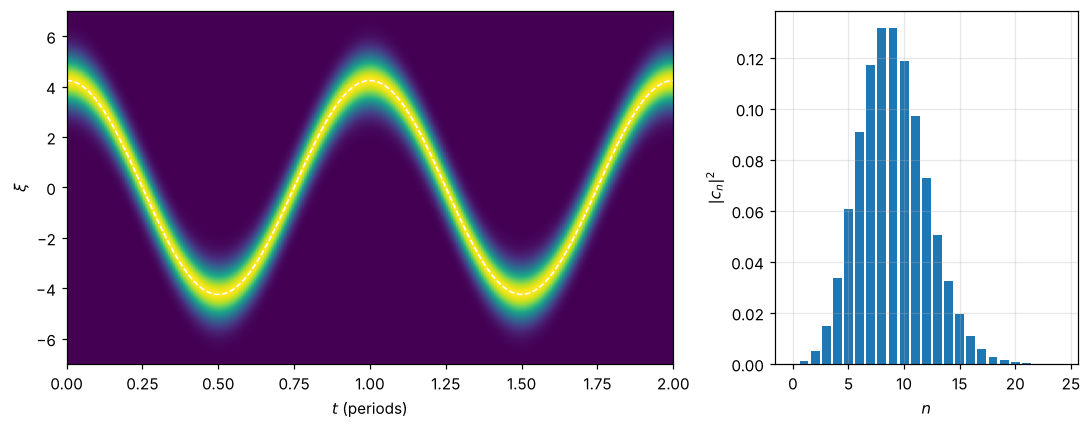

In [5]:
#| label: fig-coherent-state
#| caption: "A coherent state with α = 3 (n̄ = 9), built from the first 40 oscillator states and evolved exactly. Left, |Ψ(ξ, t)|² over two periods; the Gaussian swings between ±√2|α| without spreading, and the dashed line is the classical path. Right, the Poisson distribution of n."
from scipy.special import eval_hermite, factorial
alpha = 3.0; Nmax = 40
X = np.linspace(-7, 7, 300)
phi = np.array([(np.pi**-0.25 / np.sqrt(2.0**k * factorial(k))) * eval_hermite(k, X) * np.exp(-X**2 / 2) for k in range(Nmax)])
c = np.exp(-alpha**2 / 2) * alpha**np.arange(Nmax) / np.sqrt(factorial(np.arange(Nmax)))
ts = np.linspace(0, 4 * np.pi, 240)
dens = np.array([abs((c * np.exp(-1j * (np.arange(Nmax) + 0.5) * t)) @ phi)**2 for t in ts])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [2, 1]})
a1.imshow(dens.T, origin="lower", aspect="auto", extent=[0, 2, X[0], X[-1]], cmap="viridis")
a1.plot(ts / (2 * np.pi), np.sqrt(2) * alpha * np.cos(ts), "w--", lw=1)
a1.set_xlabel("$t$ (periods)"); a1.set_ylabel("$\\xi$"); a1.grid(False)
a2.bar(np.arange(Nmax)[:25], (c**2)[:25]); a2.set_xlabel("$n$"); a2.set_ylabel("$|c_n|^2$")
plt.tight_layout(); plt.show()

In [6]:
# Check: <x>(t) and sigma_x(t) for the coherent state, from the matrices of x in the truncated basis
nn = np.arange(Nmax)
Xm = (np.diag(np.sqrt(nn[1:]), 1) + np.diag(np.sqrt(nn[1:]), -1)) / np.sqrt(2)     # xi = (a+ + a-)/sqrt2
for t in [0, np.pi / 2, np.pi]:
    ct = c * np.exp(-1j * (nn + 0.5) * t)
    xm = np.real(ct.conj() @ Xm @ ct); x2 = np.real(ct.conj() @ Xm @ Xm @ ct)
    display(Math(rf"\omega t = {t:.3f}:\quad \langle\xi\rangle = {xm:+.4f},\quad \sigma_\xi = {np.sqrt(x2 - xm**2):.4f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Looking Ahead to Level 3

Sakurai moves the time dependence from the state into the operators (the **Heisenberg picture**). For the oscillator, $\hat a_-(t) = \hat a_-e^{-i\omega t}$, so $\hat x(t) = \hat x(0)\cos\omega t + \frac{\hat p(0)}{m\omega}\sin\omega t$: the classical solution, now as an operator equation. **Squeezed states** reduce $\sigma_x$ below the ground-state width at the cost of a larger $\sigma_p$, still with $\sigma_x\sigma_p = \hbar/2$ at some instants; they improve the sensitivity of gravitational-wave detectors today.

## Exercises

### Exercises

1. Use ladder operators to show $\langle n|\hat x|n\rangle = 0$ and find $\langle n|\hat p^2|n\rangle$.
2. Find $\sigma_x\sigma_p$ for the stationary state $\psi_n$.
3. A particle is in $\Psi(x, 0) = \tfrac{1}{\sqrt2}(\psi_0 + \psi_1)$. Find $\langle x\rangle(t)$.
4. Show that the coherent state {eq}`eq-coherent-state` is normalized and that $\langle n\rangle = |\alpha|^2$, $\sigma_n = |\alpha|$.
5. A 1 g mass on a spring with $\omega = 10$ s⁻¹ swings with amplitude 1 cm. Estimate $\bar n = |\alpha|^2$. Is a quantum description needed?

:::{dropdown} Hints
1. $\hat x\propto\hat a_+ + \hat a_-$ changes $n$ by $\pm1$.
2. Combine $\langle x^2\rangle$ and $\langle p^2\rangle$.
3. $\langle x\rangle$ involves $\langle0|\hat x|1\rangle = \sqrt{\hbar/2m\omega}$.
4. $\sum|\alpha|^{2n}/n! = e^{|\alpha|^2}$; for $\langle n\rangle$, use $\hat a_+\hat a_-$.
5. $E = \tfrac12m\omega^2A^2\approx\bar n\hbar\omega$.
:::

:::{dropdown} Answers
1. $\langle n|\hat p^2|n\rangle = \tfrac12\hbar m\omega(2n + 1)$.
2. $\sigma_x\sigma_p = (n + \tfrac12)\hbar$.
3. $\langle x\rangle = \sqrt{\hbar/2m\omega}\cos\omega t$.
4. $\langle\alpha|\alpha\rangle = e^{-|\alpha|^2}e^{|\alpha|^2} = 1$; $\langle\hat a_+\hat a_-\rangle = |\alpha|^2$, and the Poisson variance equals the mean.
5. $E = 5\times10^{-6}$ J, $\hbar\omega = 1.05\times10^{-33}$ J, $\bar n\approx5\times10^{27}$. The relative uncertainty $1/\sqrt{\bar n}$ is $\sim10^{-14}$: classical.
:::

## Summary

- Every smooth minimum is an oscillator for small motions; $E_n = (n + \tfrac12)\hbar\omega$.
- $\hat a_\pm$ factor $\hat H$ thanks to $[\hat a_-, \hat a_+] = 1$; they step $n$ by one with factors $\sqrt{n+1}$, $\sqrt n$.
- $\hat a_-\psi_0 = 0$ gives the Gaussian ground state; $\hat x$, $\hat p$ in terms of $\hat a_\pm$ make expectation values algebraic.
- Coherent states (eigenstates of $\hat a_-$) have Poisson $n$, follow the classical trajectory, and never spread.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.